# Real ORD inputs, yields and scaffold support

Executed research analysis on real local inputs or committed aggregate reports. Historical/validation scope is labeled explicitly. No test rescoring occurs. Use the isolated repository environment plus Jupyter, pandas and matplotlib.

In [1]:
from pathlib import Path
import os, json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
os.chdir(ROOT)
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path: sys.path.insert(0, str(path))
FIGURES = ROOT / 'docs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
def show_figure(fig, name):
    path = FIGURES / (name + '.png')
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
print('Executed analysis; Python', sys.version.split()[0])
print('Only aggregate outputs and figures are retained; raw rows/weights remain ignored.')


Executed analysis; Python 3.14.2
Only aggregate outputs and figures are retained; raw rows/weights remain ignored.


## Production acquisition
Acquisition is opt-in and verifies pinned source bytes or saves a dated source receipt. Defaults preserve cached files. The analysis below is retrospective documentation executed after the study was frozen; its exploratory summaries were not used to tune a new model.

In [2]:
RUN_FETCH = False
if RUN_FETCH:
    import subprocess
    assert not Path('data/external/az.parquet').exists(), 'Preserve cached source bytes'
    subprocess.run([sys.executable,'-m','reaction_gnn.cli','fetch'],check=True)
    subprocess.run([sys.executable,'-m','reaction_gnn.cli','prepare'],check=True)
    from reaction_gnn.quantities import prepare_quantitative
    print(prepare_quantitative('data/external/az.parquet','data/processed/reactions-quantity-v2.json'))
print('Acquisition/preparation opt-in enabled:', RUN_FETCH)


Acquisition/preparation opt-in enabled: False


## Pinned real AstraZeneca ELN cohort
740 of 750 records meet unambiguous desired-product percentage-yield and input checks. Amounts are pre-reaction fields; measured outcomes never enter features. This notebook displays only aggregates/histograms, not raw reactions or row tables. License/provenance are in docs/ORD-LICENSE.txt and docs/dataset-provenance.json.

In [3]:
source=Path('data/processed/reactions-quantity-v2.json')
raw=source.read_bytes();dataset=json.loads(raw);records=dataset['records']
print('Processed SHA256:',hashlib.sha256(raw).hexdigest())
print('Retained:',len(records),'raw:',dataset['raw_rows'],'excluded:',dataset['dropped'])
rows=[]
for record in records:
    components=record['components']
    rows.append({'yield_percent':record['yield_percent'],'temperature_c':record['temperature_c'],'components':len(components),'known_moles':sum(c.get('moles') is not None for c in components),'known_volumes':sum(c.get('volume_l') is not None for c in components)})
frame=pd.DataFrame(rows)
display(frame.describe().T)

Processed SHA256: 111883fb23471799211848402f88abde643d688586ed295e7f468061dbdae766
Retained: 740 raw: 750 excluded: {'Need one unambiguous desired-product percentage yield in [0,100]': 6, 'Nonfinite temperature': 4}


,count,mean,std,min,25%,50%,75%,max
yield_percent,740.0,38.333378,28.946837,0.0,10.4425,39.434999,61.470001,100.0
temperature_c,740.0,107.967568,22.856711,20.0,100.0000,100.000000,120.000000,200.0
components,740.0,5.987838,0.109684,5.0,6.0000,6.000000,6.000000,6.0
known_moles,740.0,4.997297,0.051952,4.0,5.0000,5.000000,5.000000,5.0
known_volumes,740.0,0.990541,0.096864,0.0,1.0000,1.000000,1.000000,1.0


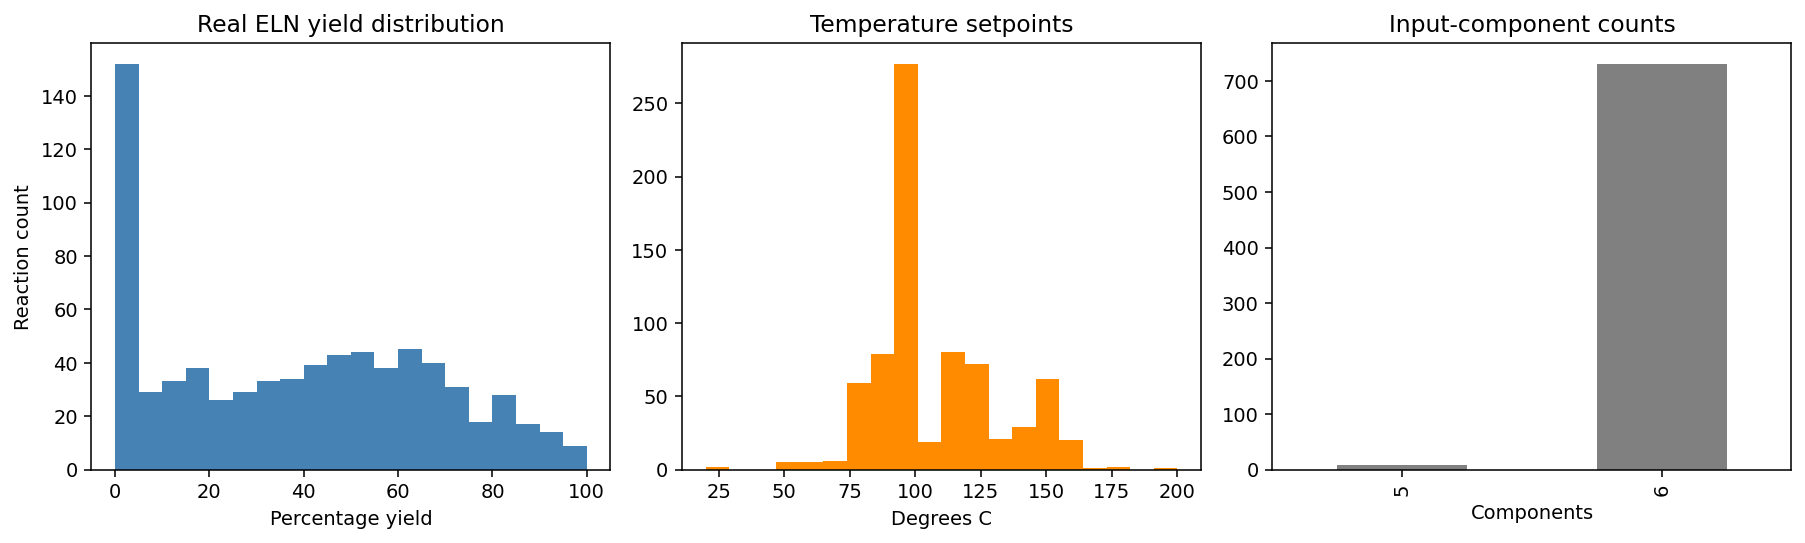

In [4]:
fig,axes=plt.subplots(1,3,figsize=(13,4))
axes[0].hist(frame.yield_percent,bins=np.arange(0,105,5),color='steelblue')
axes[0].set(title='Real ELN yield distribution',xlabel='Percentage yield',ylabel='Reaction count')
axes[1].hist(frame.temperature_c.dropna(),bins=20,color='darkorange')
axes[1].set(title='Temperature setpoints',xlabel='Degrees C')
frame.components.value_counts().sort_index().plot.bar(ax=axes[2],color='gray')
axes[2].set(title='Input-component counts',xlabel='Components')
show_figure(fig,'reaction_real_eln_distributions')

## Scaffold-grouped support and missingness
The split group is the principal largest-reactant Murcko scaffold, with an acyclic fallback. It does not remove all reagent or substrate overlap. No source ID, group ID or outcome is a feature.

In [5]:
from reaction_gnn.quantity_study import partitions
development,test,folds=partitions(dataset)
support=[]
for fold in range(3):
    chosen=[row for row in development if folds[row['group']]==fold]
    support.append({'fold':fold,'validation_reactions':len(chosen),'validation_groups':len({row['group'] for row in chosen})})
display(pd.DataFrame(support))
print('Development/test counts:',len(development),len(test))
print('Mole/volume support means:',frame[['known_moles','known_volumes']].mean().to_dict())

C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,fold,validation_reactions,validation_groups
0,0,264,37
1,1,119,36
2,2,227,36


Development/test counts: 610 130
Mole/volume support means: {'known_moles': 4.9972972972972975, 'known_volumes': 0.9905405405405405}
